In [4]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 914.9/914.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 8.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]


In [1]:
!pip uninstall -y tensorflow
!pip install tensorflow-macos tensorflow-metal

Found existing installation: tensorflow 2.21.0
Uninstalling tensorflow-2.21.0:
  Successfully uninstalled tensorflow-2.21.0
  Using cached tensorflow_macos-2.16.2-cp310-cp310-macosx_12_0_arm64.whl.metadata (3.3 kB)
  Using cached tensorflow_metal-1.2.0-cp310-cp310-macosx_12_0_arm64.whl.metadata (1.3 kB)
  Using cached tensorflow-2.16.2-cp310-cp310-macosx_12_0_arm64.whl.metadata (4.1 kB)
  Using cached ml_dtypes-0.3.2-cp310-cp310-macosx_10_9_universal2.whl.metadata (20 kB)
  Using cached tensorboard-2.16.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached tensorflow_io_gcs_filesystem-0.37.1-cp310-cp310-macosx_12_0_arm64.whl.metadata (14 kB)
  Using cached numpy-1.26.4-cp310-cp310-macosx_11_0_arm64.whl.metadata (61 kB)
  Using cached tensorboard_data_server-0.7.2-py3-none-any.whl.metadata (1.1 kB)
Using cached tensorflow_macos-2.16.2-cp310-cp310-macosx_12_0_arm64.whl (2.1 kB)
Using cached tensorflow-2.16.2-cp310-cp310-macosx_12_0_arm64.whl (227.0 MB)
Using cached ml_dtypes-0.3.2-cp310-cp

In [2]:
!pip install tensorflow

In [18]:
import numpy as np 
import optuna
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVR 
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [3]:
import tensorflow as tf

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPUs Available: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow Version: 2.16.2
GPUs Available: 1


In [56]:
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Input, LSTM, Dense 
from tensorflow.keras.optimizers import Adam

# Load & Preprocessing

In [20]:
df = pd.read_excel("/Users/asyzyni/Desktop/Data Rapih Capstone/Data Capstone Fix BGt.xlsx")
df.head()

,Tanggal,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
0,2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
1,2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2,2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
3,2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
4,2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Tanggal                                1826 non-null   datetime64[ns]
 1   Kelembapan Rata-Rata Udara Harian (%)  1826 non-null   float64       
 2   Temperatur Rata-Rata Harian            1826 non-null   float64       
 3   Temperatur Maksimum Harian             1826 non-null   float64       
 4   Temperature Minimum Harian             1826 non-null   float64       
 5   Angin Rata-Rata Harian (Knot)          1826 non-null   float64       
 6   Curah Hujan                            1826 non-null   object        
 7   Penyinaran Harian (%)                  1826 non-null   float64       
 8   Penguapan Harian (mm)                  1826 non-null   float64       
 9   Tekanan Udara Harian (mb)              1826 non-null   float64 

In [23]:
# penanganan khusus TTU 
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)

/var/folders/v6/s7jbz6sn6qv9dh421jb6jbsm0000gn/T/ipykernel_2811/2679362525.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)


In [24]:
df.describe()

,Tanggal,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
count,1826,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.000000,1826.00000,1826.000000,1826.000000
mean,2020-07-01 12:00:00,78.198795,27.731134,31.847974,23.582859,3.238741,3.200931,78.87092,5.145674,1011.730668
min,2018-01-01 00:00:00,60.000000,23.700000,27.300000,0.000000,0.300000,0.000000,0.00000,-16.000000,1004.700000
25%,2019-04-02 06:00:00,74.000000,26.900000,31.200000,22.400000,2.500000,0.000000,68.80000,4.125000,1010.400000
50%,2020-07-01 12:00:00,78.000000,27.700000,31.800000,23.900000,3.000000,0.000000,93.80000,5.000000,1011.800000
75%,2021-09-30 18:00:00,83.000000,28.500000,32.600000,24.900000,3.700000,0.400000,100.00000,6.000000,1013.100000
max,2022-12-31 00:00:00,98.000000,31.700000,36.000000,28.300000,11.900000,113.700000,100.00000,19.200000,1017.500000
std,NaN,6.582577,1.379122,1.152103,1.886676,1.136730,9.725022,29.50123,1.763992,1.996787


In [25]:
df.isnull().sum()

Tanggal                                  0
Kelembapan Rata-Rata Udara Harian (%)    0
Temperatur Rata-Rata Harian              0
Temperatur Maksimum Harian               0
Temperature Minimum Harian               0
Angin Rata-Rata Harian (Knot)            0
Curah Hujan                              0
Penyinaran Harian (%)                    0
Penguapan Harian (mm)                    0
Tekanan Udara Harian (mb)                0
dtype: int64

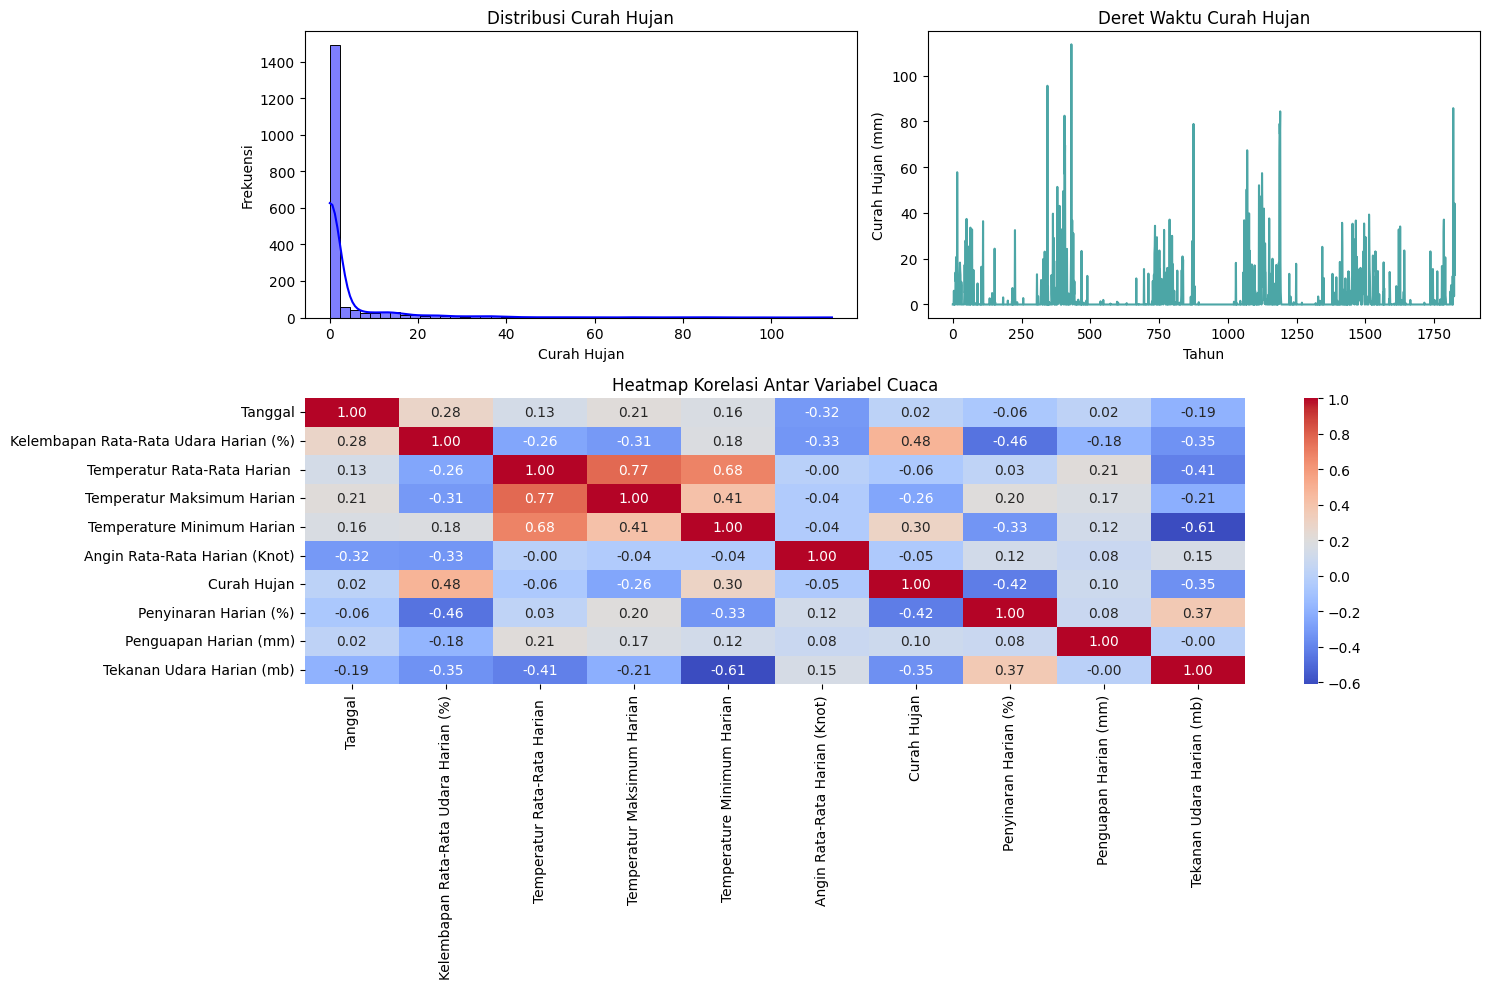

In [26]:
plt.figure(figsize=(15,10))

# plot distribusi curah hujan 
plt.subplot(2,2,1)
sns.histplot(df['Curah Hujan'],bins=50, kde=True, color='blue')
plt.title('Distribusi Curah Hujan')
plt.xlabel('Curah Hujan')
plt.ylabel('Frekuensi')

# plot curah hujan 
plt.subplot(2, 2, 2)
plt.plot(df.index, df['Curah Hujan'], color='teal', alpha=0.7)
plt.title('Deret Waktu Curah Hujan')
plt.xlabel('Tahun')
plt.ylabel('Curah Hujan (mm)')

# heatmap korelasi 
plt.subplot(2, 2, (3, 4))
# Menggunakan metode spearman karena data cuaca sering non-linear
correlation_matrix = df.corr(method='spearman')
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi Antar Variabel Cuaca')

plt.tight_layout()
plt.show()


## outlier detection 

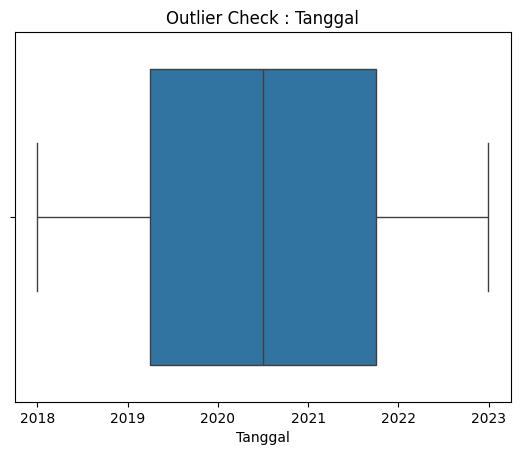

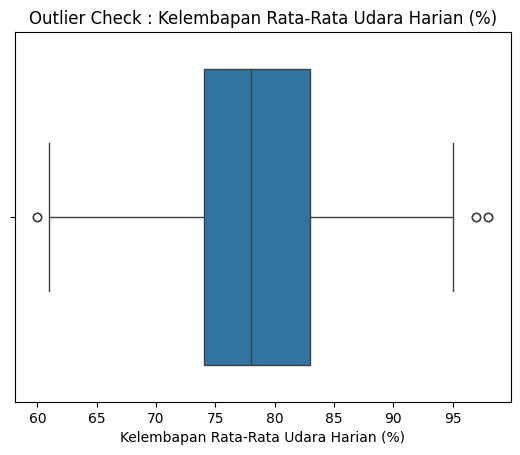

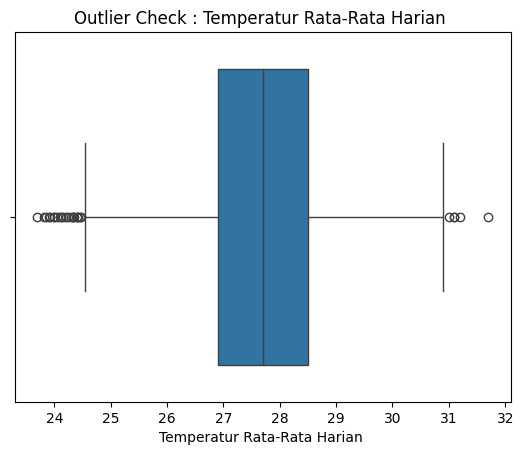

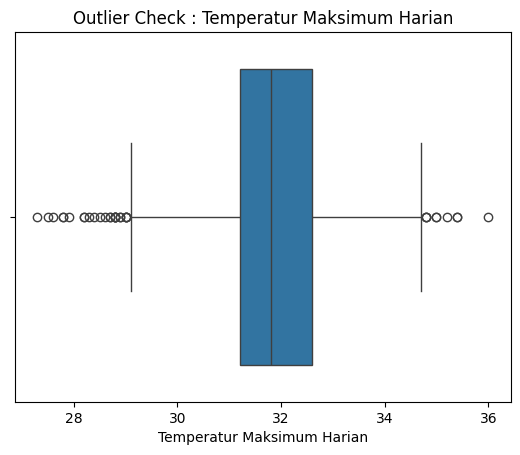

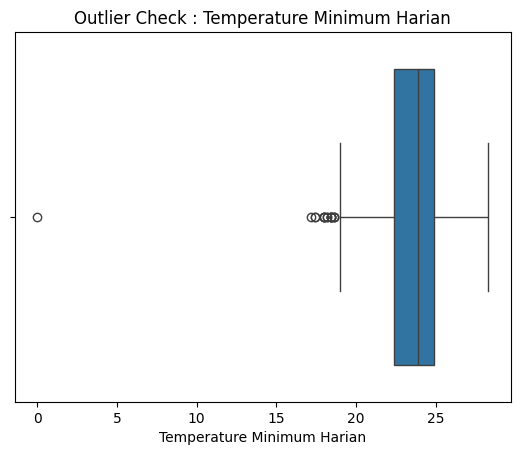

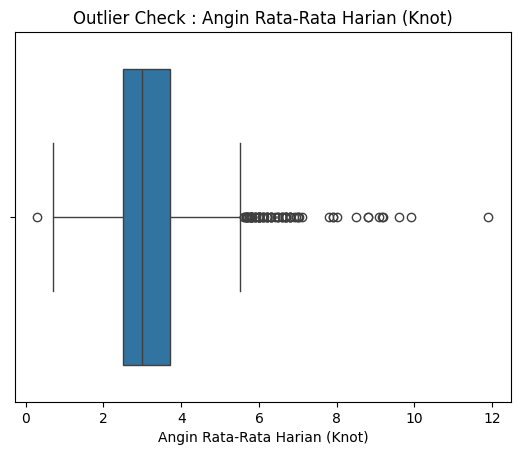

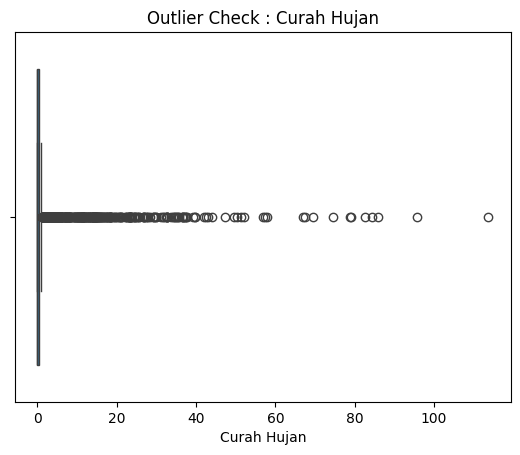

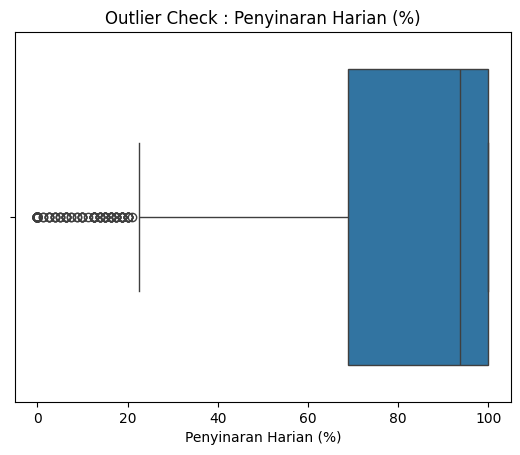

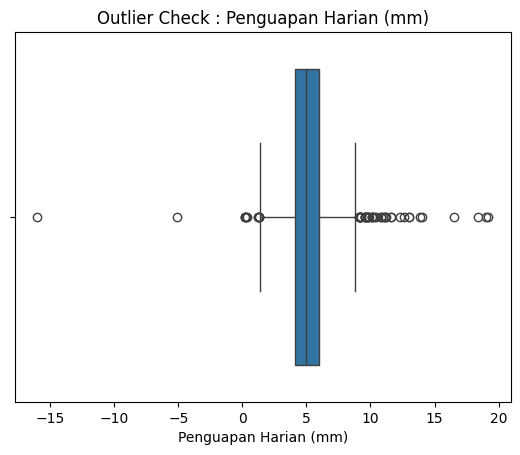

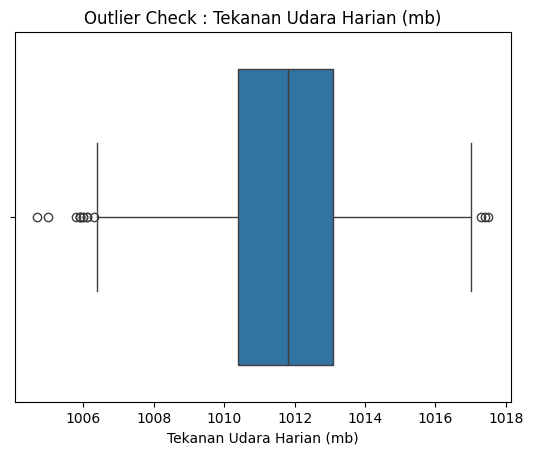

In [27]:
for col in df.columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Check : {col}")
    plt.show()

## handling outlier 

In [28]:
# log transform untuk curah hujan
df['Curah Hujan_log'] = np.log1p(df['Curah Hujan'])

In [44]:
# Step 3: Define feature list with exact names
weather_feature = ['Kelembapan Rata-Rata Udara Harian (%)',
                   'Temperatur Rata-Rata Harian',
                   'Temperatur Maksimum Harian',
                   'Temperature Minimum Harian',
                   'Angin Rata-Rata Harian (Knot)',
                   'Penyinaran Harian (%)',
                   'Penguapan Harian (mm)',
                   'Tekanan Udara Harian (mb)']

for col in weather_feature:
    if col in df.columns:
        lower_limit = df[col].quantile(0.01)
        upper_limit = df[col].quantile(0.99)
        
        df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)
        

# Train-Test Split

In [45]:
train_size = int(len(df) * 0.8)
train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

# Scaling 

In [46]:
feature_scaler = RobustScaler()
target_scaler = RobustScaler()



In [48]:
# 1. Pastikan kolom 'Curah Hujan_Log' dibuat jika belum ada
if 'Curah Hujan_Log' not in train_df.columns:
    train_df['Curah Hujan_Log'] = np.log1p(train_df['Curah Hujan'])

if 'Curah Hujan_Log' not in test_df.columns:
    test_df['Curah Hujan_Log'] = np.log1p(test_df['Curah Hujan'])

# 2. Lakukan fit transform pada data training
train_feature_sc = feature_scaler.fit_transform(train_df[weather_feature])
train_target_sc = target_scaler.fit_transform(train_df[['Curah Hujan_Log']])

# 3. Lakukan transform pada data testing
test_feature_sc = feature_scaler.transform(test_df[weather_feature])
test_target_sc = target_scaler.transform(test_df[['Curah Hujan_Log']])

In [49]:
print(train_feature_sc.shape)

(1460, 9)


In [50]:
print(train_target_sc.shape)

(1460, 1)


# Slinding Window

In [53]:
def create_sequence(features, target, time_steps):
    X, y = [], []
    
    # looping akan berhenti sebelum batas data agar tidak out of index
    for i in range(len(features) - time_steps):
        X.append(features[i : (i + time_steps)])
        y.append(target[i + time_steps])
        
    return np.array(X), np.array(y)

TIME_STEPS = 7 

X_train_seq, y_train_seq = create_sequence(train_feature_sc, train_target_sc, TIME_STEPS)
X_test_seq, y_test_seq = create_sequence(test_feature_sc, test_target_sc, TIME_STEPS)


In [54]:
# Cek dimensi akhirnya
print("--- Dimensi Data Siap Masuk LSTM ---")
print(f"X_train_seq shape: {X_train_seq.shape} -> (samples, time_steps, features)")
print(f"y_train_seq shape: {y_train_seq.shape}")
print(f"X_test_seq shape:  {X_test_seq.shape}")
print(f"y_test_seq shape:  {y_test_seq.shape}")

--- Dimensi Data Siap Masuk LSTM ---
X_train_seq shape: (1453, 7, 9) -> (samples, time_steps, features)
y_train_seq shape: (1453, 1)
X_test_seq shape:  (359, 7, 9)
y_test_seq shape:  (359, 1)


# Pipeline LSTM-SVM

## Build & Train Base LSTM

In [55]:
n_features = X_train_seq.shape[2]
lstm_units = 64 

In [58]:
base_model = Sequential()
base_model.add(Input(shape=(TIME_STEPS, n_features)))
base_model.add(LSTM(lstm_units, return_sequences=False, name='lstm_layer'))
base_model.add(Dense(1, name="output_layer"))

base_model.compile(optimizer='adam', loss='mse')

2026-04-29 07:11:32.757046: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-04-29 07:11:32.763625: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-04-29 07:11:32.765063: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-04-29 07:11:32.765448: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 07:11:32.766154: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


latih model

In [59]:
base_model.fit(X_train_seq, y_train_seq, epochs=50, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/50


2026-04-29 07:12:26.645913: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - loss: 32.2028 - val_loss: 25.5566
Epoch 2/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 24.6786 - val_loss: 23.7578
Epoch 3/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 23.0184 - val_loss: 22.9594
Epoch 4/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 22.3692 - val_loss: 22.4463
Epoch 5/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 21.8605 - val_loss: 21.8358
Epoch 6/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 21.3389 - val_loss: 22.6458
Epoch 7/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 20.9045 - val_loss: 21.8013
Epoch 8/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 20.3027 - val_loss: 20.9048
Epoch 9/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 19.8807 - val_loss: 20.5137
Epoch 10/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 19.2493 - val_loss: 20.0806
Epoch 11/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 18.6703 - val_loss: 19.5857
Epoch 12/50
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 18

## Extract Feature Using LSTM

In [60]:
feature_extractor = Model(inputs=base_model.inputs, outputs=base_model.get_layer('lstm_layer').output)

In [61]:
X_train_extracted = feature_extractor.predict(X_train_seq)
X_test_extracted = feature_extractor.predict(X_test_seq)

46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [62]:
print(f"Bentuk fitur baru untuk SVM: {X_train_extracted.shape}")

Bentuk fitur baru untuk SVM: (1453, 64)


## Bayesian Optimization

In [70]:
def objective(trial):
    c_param = trial.suggest_float('C', 1e-3, 1000, log=True)
    gamma_param = trial.suggest_categorical('gamma', ['scale', 'auto'])
    epsilon_param = trial.suggest_float('epsilon', 1e-3, 10, log=True)
    
    model_svr = SVR(kernel='rbf', C=c_param, gamma=gamma_param, epsilon=epsilon_param)
    
    model_svr.fit(X_train_extracted, y_train_seq.ravel())
    
    preds = model_svr.predict(X_test_extracted)
    
    rmse = np.sqrt(mean_squared_error(y_test_seq, preds))
    
    return rmse

study = optuna.create_study(direction='minimize', study_name='LSTM_SVM_opt')
study.optimize(objective, n_trials=50)

print("\n--- Hasil Bayesian Optimization ---")
print(f"Nilai RMSE Terbaik (Skala Log) : {study.best_value:.4f}")
print("Hyperparameter SVR Terbaik     :", study.best_params)

[I 2026-04-29 07:27:33,738] A new study created in memory with name: LSTM_SVM_opt
[I 2026-04-29 07:27:33,814] Trial 0 finished with value: 6.10797034086674 and parameters: {'C': 0.021769473749915808, 'gamma': 'auto', 'epsilon': 0.1176727266347185}. Best is trial 0 with value: 6.10797034086674.
[I 2026-04-29 07:27:33,903] Trial 1 finished with value: 5.343258099041362 and parameters: {'C': 0.08632394525047328, 'gamma': 'scale', 'epsilon': 0.003800579413998498}. Best is trial 1 with value: 5.343258099041362.
[I 2026-04-29 07:27:33,965] Trial 2 finished with value: 4.877533427224386 and parameters: {'C': 0.24873426421775713, 'gamma': 'auto', 'epsilon': 0.13297667658412687}. Best is trial 2 with value: 4.877533427224386.
[I 2026-04-29 07:27:34,051] Trial 3 finished with value: 5.286783284281501 and parameters: {'C': 27.834323710241833, 'gamma': 'auto', 'epsilon': 0.07939166279497492}. Best is trial 2 with value: 4.877533427224386.
[I 2026-04-29 07:27:34,098] Trial 4 finished with value: 6.


--- Hasil Bayesian Optimization ---
Nilai RMSE Terbaik (Skala Log) : 4.8662
Hyperparameter SVR Terbaik     : {'C': 0.2101639099177618, 'gamma': 'auto', 'epsilon': 0.20281188726296326}


# Train SVM 

In [71]:
best_params = study.best_params

final_svm_model = SVR(
    kernel='rbf', 
    C=best_params['C'], 
    gamma=best_params['gamma'],
    epsilon=best_params['epsilon']
)

In [73]:
final_svm_model.fit(X_train_extracted, y_train_seq.ravel())

SVR(C=0.2101639099177618, epsilon=0.20281188726296326, gamma='auto')

In [74]:
predict_scale_log = final_svm_model.predict(X_test_extracted)

## Inverse Transform

kembalikan array ke bentuk 2D

In [75]:
predict_scale_log = predict_scale_log.reshape(-1, 1)
y_test_seq_2d = y_test_seq.reshape(-1, 1)

inverse scaling

In [76]:
predict_log = target_scaler.inverse_transform(predict_scale_log)
y_test_log = target_scaler.inverse_transform(y_test_seq_2d)

log inverse

In [77]:
end_pred_mm = np.expm1(predict_log)
y_test_real_mm = np.expm1(y_test_log)

## Evaluation

In [78]:
rmse = np.sqrt(mean_squared_error(y_test_real_mm, end_pred_mm))
mae = mean_absolute_error(y_test_real_mm, end_pred_mm)

In [79]:
print(f"RMSE : {rmse:.2f} mm")
print(f"MAE  : {mae:.2f} mm")

RMSE : 8.11 mm
MAE  : 2.95 mm
